Two-step deer classification in ONE model
Stage 1: train backbone + antler head (Antlerless / Antlered).
Stage 2: freeze stage 1; train age head (Young / Adult) on image features
         concatenated with P(Antlerless), P(Antlered) from stage 1.
Age always uses predicted probabilities, never ground-truth antler labels.
Run cells in order, or run this file as a script. Requires torch, torchvision,
timm, numpy, pandas, Pillow, scikit-learn, matplotlib in your environment.

In [1]:
# Configuration and imports
import os
import random
from types import SimpleNamespace
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt

CFG = SimpleNamespace(
    input_root=r"X:\aanand37\Manuscript\Snapshot Wisconsin\data",
    csv_name=os.path.join("Qwen_model", "Qwen_model_visible_only_for_head_visibility.csv"),
    photos_sub=os.path.join("Snapshot_WI-Oh_Deer_Photos", "Deer"),
    out_dir=r"X:\aanand37\Manuscript\Snapshot Wisconsin\data\two_step_model",
    group_col=None,  # Set to camera/burst ID to keep related photos together.
    img_size=256, use_bbox=True, bbox_pad=0.15,
    bbox_normalized=True,  # Your CSV uses normalized x/y/width/height.
    model_name="efficientnet_b0", dropout=0.3, age_hidden=256,
    antler_epochs=50, age_epochs=50, batch_size=32,
    antler_lr=3e-4, age_lr=3e-4, weight_decay=1e-4,
    warmup_epochs=1, label_smooth=0.05, grad_clip=1.0,
    plateau_factor=0.3, plateau_patience=2, min_lr=1e-6,
    patience=5, min_delta=1e-3, val_frac=0.15, test_frac=0.15,
    seed=42, num_workers=2, amp=True, gpu_index=0,
    model_file="deer_two_step_model.pt",
)
COLS = dict(image="filename", antler="antler_status", age="age_status",
            x="bbox_origin_x", y="bbox_origin_y", w="bbox_width", h="bbox_height")
NAMES = {"antler": ["Antlerless", "Antlered"], "age": ["Young", "Adult"]}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


C:\ProgramData\Anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.2
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
# Data preparation, strict image checks, and shared splits

def prepare_data(cfg, cols):
    frame = pd.read_csv(os.path.join(cfg.input_root, cfg.csv_name))
    required = [cols[k] for k in ("image", "antler", "age")]
    if cfg.use_bbox:
        required += [cols[k] for k in ("x", "y", "w", "h")]
    if cfg.group_col:
        required.append(cfg.group_col)
    missing = set(required) - set(frame.columns)
    if missing:
        raise KeyError(f"Missing columns: {sorted(missing)}; update COLS or CFG.group_col")
    # Exact labels avoid accidentally treating 'not adult' as 'adult'.
    maps = {"antler": {"antlerless": 0, "antelerless": 0, "antlered": 1},
            "age": {"young": 0, "adult": 1}}
    for task, mapping in maps.items():
        raw = frame[cols[task]].astype(str).str.strip().str.lower()
        frame[f"y_{task}"] = raw.map(mapping)
        print(f"{task} raw labels:\n{raw.value_counts(dropna=False)}")
    valid = frame[["y_antler", "y_age"]].notna().all(axis=1)
    frame.loc[~valid].to_csv(os.path.join(cfg.out_dir, "excluded_labels.csv"), index=False)
    print(f"Dropping {(~valid).sum()} rows without BOTH recognized labels")
    frame = frame.loc[valid].copy()
    frame[["y_antler", "y_age"]] = frame[["y_antler", "y_age"]].astype(int)
    root = os.path.join(cfg.input_root, cfg.photos_sub)
    frame["path"] = frame[cols["image"]].map(
        lambda p: os.path.normcase(os.path.abspath(os.path.join(root, str(p).strip()))))
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    bad = {}
    for i, path in enumerate(frame["path"].unique(), 1):
        try:
            with Image.open(path) as im:
                im.convert("RGB").load()
        except Exception as exc:
            bad[path] = str(exc)
        if i % 250 == 0:
            print(f"Checked {i} images", flush=True)
    pd.DataFrame(list(bad.items()), columns=["path", "reason"]).to_csv(
        os.path.join(cfg.out_dir, "excluded_images.csv"), index=False)
    frame = frame.loc[~frame.path.isin(bad)].reset_index(drop=True)
    if frame.empty:
        raise ValueError("No usable rows with both labels and readable images")
    return frame


def split_data(frame, cfg):
    if not (0 < cfg.val_frac < 1 and 0 < cfg.test_frac < 1 and
            cfg.val_frac + cfg.test_frac < 1):
        raise ValueError("Validation/test fractions must be positive and sum to < 1")
    group_col = cfg.group_col or "path"
    if frame[group_col].isna().any():
        raise ValueError("Grouping column contains missing values")
    d = frame.assign(_group=frame[group_col].astype(str),
                     _joint=2 * frame.y_antler + frame.y_age)
    if d.groupby("path")._group.nunique().max() > 1:
        raise ValueError("One image has multiple group IDs; fix grouping before splitting")

    def split(part, fraction):
        # Approximate joint-label balance at group level; whole groups stay together.
        labels = part.groupby("_group")._joint.agg(lambda x: x.mode().iloc[0])
        try:
            _, held = train_test_split(labels.index, test_size=fraction,
                                       random_state=cfg.seed, stratify=labels.values)
        except ValueError:
            print("Too few groups for joint stratification; using random group split")
            _, held = train_test_split(labels.index, test_size=fraction, random_state=cfg.seed)
        mask = part._group.isin(held)
        return part.loc[~mask], part.loc[mask]

    trval, te = split(d, cfg.test_frac)
    tr, va = split(trval, cfg.val_frac / (1 - cfg.test_frac))
    parts = [tr, va, te]
    for i in range(3):
        for j in range(i):
            assert not set(parts[i]._group) & set(parts[j]._group)
            assert not set(parts[i].path) & set(parts[j].path)
    for name, part in zip(("train", "val", "test"), parts):
        if part.empty:
            raise ValueError(f"Empty {name} split")
        for task in NAMES:
            if part[f"y_{task}"].nunique() != 2:
                raise ValueError(f"{name} lacks a {task} class; revise groups/split sizes")
        print(name, len(part), "rows\n", pd.crosstab(part.y_antler, part.y_age))
    return [p.drop(columns=["_group", "_joint"]).reset_index(drop=True) for p in parts]



# 3. Load data & auto-detect the schema
The dataset is one CSV (a row per image, 10 columns, including a bounding box) plus a folder of ~4,880 JPGs.

Because a real-world CSV rarely has exactly the column names you expect, the cell below auto-detects which columns hold the filename, the Antlers label, the Age label, and the bounding box — by fuzzy keyword matching. It prints what it found so you can sanity-check. If it guesses wrong, override the COLS dict manually.

In [4]:
# Image preprocessing and paired labels

def transform(cfg, train=False):
    steps = [T.Resize((cfg.img_size, cfg.img_size))]
    if train:
        steps += [T.RandomHorizontalFlip(), T.RandomRotation(8),
                  T.ColorJitter(0.2, 0.2, 0.2, 0.02), T.RandomGrayscale(p=0.2)]
    return T.Compose(steps + [T.ToTensor(), T.Normalize(MEAN, STD)])


def load_image(row, cfg, cols):
    with Image.open(row["path"]) as im:
        image = im.convert("RGB")
    if cfg.use_bbox:
        x, y, w, h = [float(row[cols[k]]) for k in ("x", "y", "w", "h")]
        if not np.isfinite([x, y, w, h]).all() or w <= 0 or h <= 0:
            raise ValueError(f"Invalid bounding box for {row['path']}")
        if cfg.bbox_normalized:
            W, H = image.size
            x, w, y, h = x * W, w * W, y * H, h * H
        p = cfg.bbox_pad
        box = (max(0, int(x - p*w)), max(0, int(y - p*h)),
               min(image.width, int(np.ceil(x + (1+p)*w))),
               min(image.height, int(np.ceil(y + (1+p)*h))))
        if box[2] <= box[0] or box[3] <= box[1]:
            raise ValueError(f"Bounding box is outside image: {row['path']}")
        image = image.crop(box)
    return image


class DeerDataset(Dataset):
    def __init__(self, frame, cfg, cols, train=False):
        self.frame = frame.reset_index(drop=True)
        self.cfg, self.cols, self.tf = cfg, cols, transform(cfg, train)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        return (self.tf(load_image(row, self.cfg, self.cols)),
                torch.tensor([row.y_antler, row.y_age], dtype=torch.long))


def make_loader(frame, cfg, cols, train=False):
    return DataLoader(DeerDataset(frame, cfg, cols, train), batch_size=cfg.batch_size,
                      shuffle=train, drop_last=False, num_workers=cfg.num_workers,
                      pin_memory=torch.cuda.is_available())


In [5]:
# One model: image features -> antler prediction -> conditioned age prediction

class TwoStepDeerNet(nn.Module):
    def __init__(self, cfg, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(cfg.model_name, pretrained=pretrained,
                                         num_classes=0, global_pool="avg")
        n = self.backbone.num_features
        self.antler_head = nn.Sequential(nn.Dropout(cfg.dropout), nn.Linear(n, 2))
        self.age_head = nn.Sequential(nn.Linear(n + 2, cfg.age_hidden), nn.ReLU(),
                                      nn.Dropout(cfg.dropout), nn.Linear(cfg.age_hidden, 2))

    def forward(self, x):
        features = self.backbone(x)
        antler_logits = self.antler_head(features)
        antler_probs = antler_logits.float().softmax(dim=1)
        age_logits = self.age_head(torch.cat([features, antler_probs], dim=1))
        return {"antler": antler_logits, "age": age_logits}

    def set_stage(self, task):
        self.requires_grad_(False)
        if task == "antler":
            self.backbone.requires_grad_(True)
            self.antler_head.requires_grad_(True)
        else:
            self.age_head.requires_grad_(True)

    def training_mode(self, task):
        self.train()
        if task == "age":
            # Freeze BatchNorm statistics and dropout as well as stage-1 weights.
            self.backbone.eval()
            self.antler_head.eval()


@torch.no_grad()
def predict_loader(model, loader, device, amp=False):
    model.eval()
    probs, labels = {k: [] for k in NAMES}, []
    for x, y in loader:
        with torch.autocast(device.type, enabled=amp and device.type == "cuda"):
            result = model(x.to(device))
        for task in NAMES:
            probs[task].append(result[task].float().softmax(1).cpu().numpy())
        labels.append(y.numpy())
    return {k: np.concatenate(v) for k, v in probs.items()}, np.concatenate(labels)


def save_model(model, cfg, cols, path, stage, epoch, score):
    torch.save(dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()},
                    config=vars(cfg).copy(), columns=cols, label_names=NAMES,
                    decision_rule="argmax", completed_stage=stage,
                    best_epoch=epoch, validation_macro_f1=score), path)


def train_stage(model, task, tr, va, cfg, cols, device):
    model.set_stage(task)
    idx = 0 if task == "antler" else 1
    counts = np.bincount(tr[f"y_{task}"], minlength=2)
    weights = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=cfg.label_smooth)
    params = [p for p in model.parameters() if p.requires_grad]
    lr = getattr(cfg, f"{task}_lr")
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=cfg.plateau_factor, patience=cfg.plateau_patience,
        threshold=cfg.min_delta, threshold_mode="abs", min_lr=cfg.min_lr)
    amp = cfg.amp and device.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=amp)
    dl, vl = make_loader(tr, cfg, cols, True), make_loader(va, cfg, cols)
    best, significant_best, bad, step = -1.0, -1.0, 0, 0
    best_state, history = None, []
    warmup = cfg.warmup_epochs * len(dl)
    for epoch in range(1, getattr(cfg, f"{task}_epochs") + 1):
        model.training_mode(task)
        losses = []
        for x, targets in dl:
            if step < warmup:
                for group in opt.param_groups:
                    group["lr"] = lr * (step + 1) / warmup
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=amp):
                logits = model(x.to(device))[task]
                loss = criterion(logits.float(), targets[:, idx].to(device))
            scaler.scale(loss).backward()
            if cfg.grad_clip:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(params, cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            losses.append(loss.item())
            step += 1
        probs, actual = predict_loader(model, vl, device, amp)
        score = f1_score(actual[:, idx], probs[task].argmax(1), labels=[0, 1],
                         average="macro", zero_division=0)
        history.append(dict(epoch=epoch, loss=float(np.mean(losses)), val_f1=score,
                            lr=opt.param_groups[0]["lr"]))
        print(f"{task} epoch {epoch}: loss={np.mean(losses):.4f}, val macro-F1={score:.4f}", flush=True)
        if score > best:
            best = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            save_model(model, cfg, cols, os.path.join(cfg.out_dir, cfg.model_file), task, epoch, score)
        if score > significant_best + cfg.min_delta:
            significant_best, bad = score, 0
        elif epoch > cfg.warmup_epochs:
            bad += 1
        if epoch > cfg.warmup_epochs:
            scheduler.step(score)
        if bad >= cfg.patience:
            break
    if best_state is None:
        raise ValueError("Stage must have at least one training epoch")
    model.load_state_dict(best_state)
    pd.DataFrame(history).to_csv(os.path.join(cfg.out_dir, f"{task}_history.csv"), index=False)


In [6]:
# Final held-out evaluation and checkpoint loading for new images

def report_test(model, te, cfg, cols, device):
    probs, actual = predict_loader(model, make_loader(te, cfg, cols), device, cfg.amp)
    predictions = te.copy()
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    correct = []
    for idx, (task, names) in enumerate(NAMES.items()):
        pred = probs[task].argmax(1)
        correct.append(pred == actual[:, idx])
        report = classification_report(actual[:, idx], pred, labels=[0, 1],
                                       target_names=names, digits=4, zero_division=0)
        print(f"\n{task} held-out test report (argmax)\n{report}")
        with open(os.path.join(cfg.out_dir, f"{task}_report.txt"), "w") as f:
            f.write(report)
        for j, name in enumerate(names):
            predictions[f"prob_{name.lower()}"] = probs[task][:, j]
        predictions[f"predicted_{task}_status"] = [names[v] for v in pred]
        predictions[f"{task}_correct"] = correct[-1]
        cm = confusion_matrix(actual[:, idx], pred, labels=[0, 1])
        ax = axes[idx]
        ax.imshow(cm, cmap="Blues")
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=names, yticklabels=names,
               xlabel="Predicted", ylabel="Actual", title=f"{task.title()} status")
        for r in range(2):
            for c in range(2):
                ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=16,
                        color="white" if cm[r, c] > cm.max()/2 else "black")
    predictions["both_correct"] = correct[0] & correct[1]
    print(f"Both labels correct: {predictions.both_correct.mean():.4f}")
    predictions.to_csv(os.path.join(cfg.out_dir, "two_step_test_predictions.csv"), index=False)
    fig.tight_layout()
    fig.savefig(os.path.join(cfg.out_dir, "confusion_matrices.png"), dpi=180)
    plt.show()


def load_trained_model(checkpoint_path, device="cpu"):
    device = torch.device(device)
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if checkpoint["completed_stage"] != "age":
        raise ValueError("Checkpoint contains only stage 1; complete age training first")
    cfg = SimpleNamespace(**checkpoint["config"])
    model = TwoStepDeerNet(cfg, pretrained=False).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, cfg, checkpoint["columns"]


@torch.no_grad()
def predict_image(model, cfg, cols, image_path, bbox=None):
    """bbox=(x,y,width,height), normalized if cfg.bbox_normalized is True.
    Supply the deer box when the model was trained with bounding-box crops.
    No antler or age labels are needed for prediction.
    """
    row = {"path": image_path}
    if cfg.use_bbox:
        if bbox is None:
            raise ValueError("Supply bbox=(x,y,width,height), matching training preprocessing")
        row.update({cols[k]: v for k, v in zip(("x", "y", "w", "h"), bbox)})
    x = transform(cfg)(load_image(row, cfg, cols)).unsqueeze(0)
    model.eval()
    output = model(x.to(next(model.parameters()).device))
    result = {}
    for task, names in NAMES.items():
        p = output[task].float().softmax(1)[0].cpu().numpy()
        result[f"{task}_status"] = names[int(p.argmax())]
        result.update({f"prob_{name.lower()}": float(p[i]) for i, name in enumerate(names)})
    return result


GPU: NVIDIA A100-PCIE-40GB
antler raw labels:
antler_status
antlerless    3193
antlered      1344
Name: count, dtype: int64
age raw labels:
age_status
adult    3633
young     904
Name: count, dtype: int64
Dropping 0 rows without BOTH recognized labels
Checked 250 images
Checked 500 images
Checked 750 images
Checked 1000 images
Checked 1250 images
Checked 1500 images
Checked 1750 images
Checked 2000 images
Checked 2250 images
Checked 2500 images
Checked 2750 images
Checked 3000 images
Checked 3250 images
Checked 3500 images
Checked 3750 images
Checked 4000 images
Checked 4250 images
Checked 4500 images
train 3175 rows
 y_age       0     1
y_antler           
0         633  1602
1           0   940
val 681 rows
 y_age       0    1
y_antler          
0         135  344
1           0  202
test 681 rows
 y_age       0    1
y_antler          
0         136  343
1           0  202
antler epoch 1: loss=0.6207, val macro-F1=0.7614
antler epoch 2: loss=0.4643, val macro-F1=0.7523
antler epoch 3:

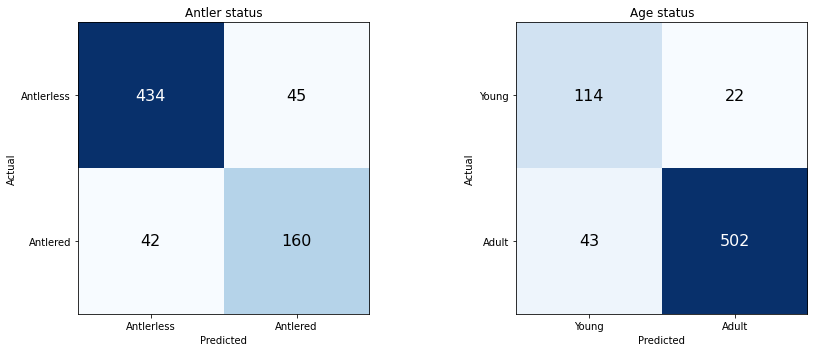

Saved model, reports, and predictions to: X:\aanand37\Manuscript\Snapshot Wisconsin\data\two_step_model


In [7]:
# Run both training stages, then evaluate the test split ONCE

def main():
    random.seed(CFG.seed)
    np.random.seed(CFG.seed)
    torch.manual_seed(CFG.seed)
    torch.cuda.manual_seed_all(CFG.seed)
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA GPU required for training; prediction also supports CPU")
    device = torch.device(f"cuda:{CFG.gpu_index}")
    torch.cuda.set_device(device)
    if os.name == "nt":
        CFG.num_workers = 0
    print("GPU:", torch.cuda.get_device_name(device))
    os.makedirs(CFG.out_dir, exist_ok=True)
    data = prepare_data(CFG, COLS)
    tr, va, te = split_data(data, CFG)
    for name, part in zip(("train", "val", "test"), (tr, va, te)):
        part.to_csv(os.path.join(CFG.out_dir, f"split_{name}.csv"), index=False)
    model = TwoStepDeerNet(CFG).to(device)
    train_stage(model, "antler", tr, va, CFG, COLS, device)
    train_stage(model, "age", tr, va, CFG, COLS, device)
    report_test(model, te, CFG, COLS, device)
    print("Saved model, reports, and predictions to:", CFG.out_dir)
    return model


if __name__ == "__main__":
    model = main()

# Example after training / in a fresh session with these definitions loaded:
# model, cfg, cols = load_trained_model(os.path.join(CFG.out_dir, CFG.model_file))
# result = predict_image(model, cfg, cols, r"X:\path\deer.jpg",
#                        bbox=(0.2687, 0.1066, 0.5043, 0.6933))
# print(result)

In [7]:
# Example after training / in a fresh session with these definitions loaded:
model, cfg, cols = load_trained_model(os.path.join(CFG.out_dir, CFG.model_file))
result = predict_image(model, cfg, cols, r"X:\path\deer.jpg",
                       bbox=(0.2687, 0.1066, 0.5043, 0.6933))
print(result)

UnpicklingError: Weights only load failed. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution.Do it only if you get the file from a trusted source. WeightsUnpickler error: Unsupported class numpy.core.multiarray.scalar

#### =======================JOINT EVALUATION (Antlers + Age Joint Classification & Exact-Match Metrics)Follows Rubric: Image is only correct if BOTH Antler AND Age predictions match.Classes:0: Adult / Antlerless1: Adult / Antlered2: Young / Antlerless3: Young / Antlered
=============================================================================

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, f1_score

JOINT_NAMES = [
"Adult Antlerless",
"Adult Antlered",
"Young Antlerless",
"Young Antlered",
]

def to_joint_id(antler, age):
return (np.asarray(age) * 2) + np.asarray(antler)